If we label a 123to321 type modal transformation model that has fully utilized all its neurons as having a 100% multi-modal fusion degree, then the method of recovering multiple modalities from a single modality (1to123) is what we need to consider next. Ensuring that the temporal and spatial correspondences are consistent when reading the dataset can further enhance the potential. Therefore, WSG theoretically has the potential to surpass the upper limit of existing models (if we define the upper limit of existing models as 100%). 

ie., in a nutshell, under the same data volume and training time, the ratio of achieving n% multimodal fusion degree to a certain parameter quantity, the more, the better.

## 1. Generate Dataset

In [1]:
import numpy as np
import os
from pathlib import Path

# Create data directories
base_path = Path("data")
normal_input_path = base_path / "normal_input"
wsg_input_path = base_path / "wsg_input"

normal_input_path.mkdir(parents=True, exist_ok=True)
wsg_input_path.mkdir(parents=True, exist_ok=True)

print(f"Directories created:")
print(f"  - {normal_input_path}")
print(f"  - {wsg_input_path}")

Directories created:
  - data\normal_input
  - data\wsg_input


In [2]:
# Generate normal_input files: 100 files each for 3 separate channels
print("Generating normal_input files...")

# Define channel configurations (can easily extend or modify)
channels = {
    1: {"name": "channel1", "value": 1},
    2: {"name": "channel2", "value": 2}, 
    3: {"name": "channel3", "value": 3}
}

for channel_id, config in channels.items():
    for i in range(100):
        # Create 256x256 array with 1 channel
        array = np.ones((256, 256, 1), dtype=np.float32) * config["value"]
        
        # Save as npz file with descriptive naming
        filename = f"data_mock_{config['name']}_{i:03d}.npz"
        filepath = normal_input_path / filename
        np.savez_compressed(filepath, data=array)
    
    print(f"  Created 100 files for {config['name']} (value={config['value']})")

print(f"Total normal_input files created: {len(list(normal_input_path.glob('*.npz')))}")

Generating normal_input files...
  Created 100 files for channel1 (value=1)
  Created 100 files for channel2 (value=2)
  Created 100 files for channel3 (value=3)
Total normal_input files created: 300


In [6]:
# Generate wsg_input files: 300 files with 3 channels [1, 2, 3]
print("\nGenerating wsg_input files...")

for i in range(100):
    # Create 256x256 array with 3 channels
    array = np.zeros((256, 256, 3), dtype=np.float32)
    array[:, :, 0] = 1  # Channel 0: value 1
    array[:, :, 1] = 2  # Channel 1: value 2
    array[:, :, 2] = 3  # Channel 2: value 3
    
    # Save as npz file
    filename = f"data_{i:03d}.npz"
    filepath = wsg_input_path / filename
    np.savez_compressed(filepath, data=array)
    
    if (i + 1) % 50 == 0:
        print(f"  Created {i + 1} files")

print(f"Total wsg_input files created: {len(list(wsg_input_path.glob('*.npz')))}")


Generating wsg_input files...
  Created 50 files
  Created 100 files
Total wsg_input files created: 100


### 2. Generate Target Datasets (with reversed channel values: 3, 2, 1)

In [10]:
# Create target directories
normal_target_path = base_path / "normal_target"
wsg_target_path = base_path / "wsg_target"

normal_target_path.mkdir(parents=True, exist_ok=True)
wsg_target_path.mkdir(parents=True, exist_ok=True)

print(f"Target directories created:")
print(f"  - {normal_target_path}")
print(f"  - {wsg_target_path}")

Target directories created:
  - data\normal_target
  - data\wsg_target


In [11]:
# Generate normal_target files: 100 files each for 3 separate channels (reversed values)
print("\nGenerating normal_target files...")

# Define channel configurations with REVERSED values (3, 2, 1)
channels_reversed = {
    1: {"name": "channel1", "value": 3},  # Channel 1 now has value 3
    2: {"name": "channel2", "value": 2},  # Channel 2 keeps value 2
    3: {"name": "channel3", "value": 1}   # Channel 3 now has value 1
}

for channel_id, config in channels_reversed.items():
    for i in range(100):
        # Create 256x256 array with 1 channel
        array = np.ones((256, 256, 1), dtype=np.float32) * config["value"]
        
        # Save as npz file with descriptive naming
        filename = f"data_mock_{config['name']}_{i:03d}.npz"
        filepath = normal_target_path / filename
        np.savez_compressed(filepath, data=array)
    
    print(f"  Created 100 files for {config['name']} (value={config['value']})")

print(f"Total normal_target files created: {len(list(normal_target_path.glob('*.npz')))}")


Generating normal_target files...
  Created 100 files for channel1 (value=3)
  Created 100 files for channel2 (value=2)
  Created 100 files for channel3 (value=1)
Total normal_target files created: 300


In [12]:
# Generate wsg_target files: 100 files with 3 channels fused together (reversed values)
print("\nGenerating wsg_target files...")

for i in range(100):  # 100 files total
    # Create 256x256 array with 3 channels - REVERSED values (3, 2, 1)
    array = np.zeros((256, 256, 3), dtype=np.float32)
    array[:, :, 0] = 3  # Channel 0: value 3 (was 1)
    array[:, :, 1] = 2  # Channel 1: value 2 (stays same)
    array[:, :, 2] = 1  # Channel 2: value 1 (was 3)
    
    # Save as npz file
    filename = f"data_fused_{i:03d}.npz"
    filepath = wsg_target_path / filename
    np.savez_compressed(filepath, data=array)
    
    if (i + 1) % 50 == 0:
        print(f"  Created {i + 1} files")

print(f"Total wsg_target files created: {len(list(wsg_target_path.glob('*.npz')))}")
print("\nSummary:")
print("  Input:  channels [1, 2, 3]")
print("  Target: channels [3, 2, 1]")


Generating wsg_target files...
  Created 50 files
  Created 100 files
Total wsg_target files created: 100

Summary:
  Input:  channels [1, 2, 3]
  Target: channels [3, 2, 1]


## 3. Verify Generated Data

In [ ]:
# Verify normal_input
sample_files = list(normal_input_path.glob('*.npz'))
if sample_files:
    sample_normal = sample_files[0]
    data = np.load(sample_normal)
    print(f"Normal input sample: {sample_normal.name}")
    print(f"  Shape: {data['data'].shape}")
    print(f"  Unique values: {np.unique(data['data'])}")
    print(f"  Data type: {data['data'].dtype}")
else:
    print("No files found in normal_input directory")

# Verify wsg_input
sample_files = list(wsg_input_path.glob('*.npz'))
if sample_files:
    sample_wsg = sample_files[0]
    data = np.load(sample_wsg)
    print(f"\nWSG input sample: {sample_wsg.name}")
    print(f"  Shape: {data['data'].shape}")
    print(f"  Channel 0 unique values: {np.unique(data['data'][:,:,0])}")
    print(f"  Channel 1 unique values: {np.unique(data['data'][:,:,1])}")
    print(f"  Channel 2 unique values: {np.unique(data['data'][:,:,2])}")
    print(f"  Data type: {data['data'].dtype}")
else:
    print("No files found in wsg_input directory")

# Verify normal_target
sample_files = list(normal_target_path.glob('*.npz'))
if sample_files:
    sample_normal = sample_files[0]
    data = np.load(sample_normal)
    print(f"\nNormal target sample: {sample_normal.name}")
    print(f"  Shape: {data['data'].shape}")
    print(f"  Unique values: {np.unique(data['data'])}")
    print(f"  Data type: {data['data'].dtype}")
else:
    print("No files found in normal_target directory")

# Verify wsg_target
sample_files = list(wsg_target_path.glob('*.npz'))
if sample_files:
    sample_wsg = sample_files[0]
    data = np.load(sample_wsg)
    print(f"\nWSG target sample: {sample_wsg.name}")
    print(f"  Shape: {data['data'].shape}")
    print(f"  Channel 0 unique values: {np.unique(data['data'][:,:,0])}")
    print(f"  Channel 1 unique values: {np.unique(data['data'][:,:,1])}")
    print(f"  Channel 2 unique values: {np.unique(data['data'][:,:,2])}")
    print(f"  Data type: {data['data'].dtype}")
else:
    print("No files found in wsg_target directory")

## 4. Multimodal Fusion Experiments

### Key Concept:
- **Normal approach**: 3 separate modalities → Model → Combined representation (123→321)
- **WSG approach**: Store all modalities in single image → Recover multiple modalities (1→123)
- **Goal**: Achieve higher fusion efficiency with temporal-spatial correspondence

In [49]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from scipy import linalg
from tqdm import tqdm

# Simple UNet Block
class UNetBlock(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

# Base UNet (simplified, ~50K params)
class SimpleUNet(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        # Encoder
        self.e1 = UNetBlock(in_channels, 16)
        self.pool1 = nn.MaxPool2d(2)
        self.e2 = UNetBlock(16, 32)
        self.pool2 = nn.MaxPool2d(2)
        # Bottleneck
        self.b = UNetBlock(32, 64)
        # Decoder
        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.d1 = UNetBlock(64, 32)
        self.up2 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.d2 = UNetBlock(32, 16)
        # Output
        self.out = nn.Conv2d(16, out_channels, 1)
        
    def forward(self, x):
        # Encoder
        s1 = self.e1(x)
        p1 = self.pool1(s1)
        s2 = self.e2(p1)
        p2 = self.pool2(s2)
        # Bottleneck
        b = self.b(p2)
        # Decoder
        u1 = self.up1(b)
        d1 = self.d1(torch.cat([u1, s2], 1))
        u2 = self.up2(d1)
        d2 = self.d2(torch.cat([u2, s1], 1))
        return self.out(d2)

# 1. WSG Method (1-to-1 fusion)
class WSGFusion(SimpleUNet):
    def __init__(self):
        super().__init__(3, 3)  # 3 channels in, 3 channels out
        
# 2. Early Fusion (concatenate at input)
class EarlyFusion(SimpleUNet):
    def __init__(self):
        super().__init__(3, 3)  # Process 3 separate channels as one input
        
# 3. Middle Fusion (feature-level) - FIXED
class MiddleFusion(nn.Module):
    def __init__(self):
        super().__init__()
        # Three separate encoders for each channel
        self.enc1 = nn.Sequential(UNetBlock(1, 16), nn.MaxPool2d(2))
        self.enc2 = nn.Sequential(UNetBlock(1, 16), nn.MaxPool2d(2))
        self.enc3 = nn.Sequential(UNetBlock(1, 16), nn.MaxPool2d(2))
        # Fusion and decoder
        self.fusion = UNetBlock(48, 32)  # 3x16=48
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(32, 16, 2, stride=2),
            UNetBlock(16, 16),
            nn.Conv2d(16, 3, 1)
        )
        
    def forward(self, x1, x2, x3):
        # Encode separately
        f1 = self.enc1(x1)
        f2 = self.enc2(x2)
        f3 = self.enc3(x3)
        # Fuse features
        fused = torch.cat([f1, f2, f3], 1)
        fused = self.fusion(fused)
        # Decode to output - upsample to match input size
        output = self.decoder(fused)
        # Ensure output matches input size
        output = F.interpolate(output, size=(256, 256), mode='bilinear', align_corners=False)
        return output
        
# 4. Late Fusion (decision-level) - FIXED
class LateFusion(nn.Module):
    def __init__(self):
        super().__init__()
        # Three complete paths
        self.path1 = SimpleUNet(1, 1)
        self.path2 = SimpleUNet(1, 1)
        self.path3 = SimpleUNet(1, 1)
        
    def forward(self, x1, x2, x3):
        # Process separately
        o1 = self.path1(x1)
        o2 = self.path2(x2)
        o3 = self.path3(x3)
        # Concatenate outputs
        return torch.cat([o1, o2, o3], 1)

# 5. Concatenation Fusion (Simple concat strategy)
class ConcatFusion(nn.Module):
    def __init__(self):
        super().__init__()
        # Direct concatenation followed by processing
        self.fusion_conv = nn.Conv2d(3, 16, 1)  # 1x1 conv to mix channels
        self.process = SimpleUNet(16, 3)
        
    def forward(self, x):
        # Simple concatenation strategy
        fused = self.fusion_conv(x)
        return self.process(fused)

# 6. Attention Fusion (Self-attention and cross-attention)
class AttentionFusion(nn.Module):
    def __init__(self):
        super().__init__()
        # Channel-wise attention
        self.channel_attention = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(3, 3, 1),
            nn.Sigmoid()
        )
        # Spatial attention
        self.spatial_attention = nn.Sequential(
            nn.Conv2d(3, 1, 7, padding=3),
            nn.Sigmoid()
        )
        # Process with attention weights
        self.process = SimpleUNet(3, 3)
        
    def forward(self, x):
        # Apply channel attention
        ca = self.channel_attention(x)
        x = x * ca
        # Apply spatial attention
        sa = self.spatial_attention(x)
        x = x * sa
        # Process
        return self.process(x)

# 7. Contrastive Fusion (Inspired by CLIP) - FIXED
class ContrastiveFusion(nn.Module):
    def __init__(self):
        super().__init__()
        # Simple encoder-decoder architecture
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 2, stride=2),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 16, 2, stride=2),
            nn.ReLU(),
            nn.Conv2d(16, 3, 1)
        )
        
    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

print("Models defined (with fixes):")
print(f"  - WSGFusion: ~{sum(p.numel() for p in WSGFusion().parameters())/1000:.1f}K params")
print(f"  - EarlyFusion: ~{sum(p.numel() for p in EarlyFusion().parameters())/1000:.1f}K params")
print(f"  - MiddleFusion: ~{sum(p.numel() for p in MiddleFusion().parameters())/1000:.1f}K params")
print(f"  - LateFusion: ~{sum(p.numel() for p in LateFusion().parameters())/1000:.1f}K params")
print(f"  - ConcatFusion: ~{sum(p.numel() for p in ConcatFusion().parameters())/1000:.1f}K params")
print(f"  - AttentionFusion: ~{sum(p.numel() for p in AttentionFusion().parameters())/1000:.1f}K params")
print(f"  - ContrastiveFusion: ~{sum(p.numel() for p in ContrastiveFusion().parameters())/1000:.1f}K params")

Models defined (with fixes):
  - WSGFusion: ~117.7K params
  - EarlyFusion: ~117.7K params
  - MiddleFusion: ~37.7K params
  - LateFusion: ~352.2K params
  - ConcatFusion: ~119.7K params
  - AttentionFusion: ~117.9K params
  - ContrastiveFusion: ~29.7K params


In [50]:
# Additional WSG-based fusion strategies (for ablation study)

# 8. WSG + Attention Fusion
class WSGAttentionFusion(nn.Module):
    def __init__(self):
        super().__init__()
        # Channel-wise attention for WSG input
        self.channel_attention = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(3, 3, 1),
            nn.Sigmoid()
        )
        # Spatial attention
        self.spatial_attention = nn.Sequential(
            nn.Conv2d(3, 1, 7, padding=3),
            nn.Sigmoid()
        )
        # Process with WSG-style UNet
        self.process = SimpleUNet(3, 3)
        
    def forward(self, x):
        # Apply channel attention
        ca = self.channel_attention(x)
        x = x * ca
        # Apply spatial attention
        sa = self.spatial_attention(x)
        x = x * sa
        # Process with WSG architecture
        return self.process(x)

# 9. WSG + Contrastive Fusion
class WSGContrastiveFusion(nn.Module):
    def __init__(self):
        super().__init__()
        # Contrastive encoder for WSG input
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        # WSG-style decoder
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 2, stride=2),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 16, 2, stride=2),
            nn.ReLU(),
            nn.Conv2d(16, 3, 1)
        )
        
    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

print("\nAdditional WSG-based models for ablation:")
print(f"  - WSGAttentionFusion: ~{sum(p.numel() for p in WSGAttentionFusion().parameters())/1000:.1f}K params")
print(f"  - WSGContrastiveFusion: ~{sum(p.numel() for p in WSGContrastiveFusion().parameters())/1000:.1f}K params")


Additional WSG-based models for ablation:
  - WSGAttentionFusion: ~117.9K params
  - WSGContrastiveFusion: ~29.7K params


In [51]:
# Dataset and Training Setup
import time

class MultiModalDataset(Dataset):
    def __init__(self, input_path, target_path, wsg_mode=False):
        self.wsg_mode = wsg_mode
        if wsg_mode:
            # WSG: single fused files
            self.input_files = sorted(input_path.glob('*.npz'))
            self.target_files = sorted(target_path.glob('*.npz'))
        else:
            # Normal: separate channel files
            self.ch1_files = sorted(input_path.glob('*channel1*.npz'))
            self.ch2_files = sorted(input_path.glob('*channel2*.npz'))
            self.ch3_files = sorted(input_path.glob('*channel3*.npz'))
            self.tgt_ch1_files = sorted(target_path.glob('*channel1*.npz'))
            self.tgt_ch2_files = sorted(target_path.glob('*channel2*.npz'))
            self.tgt_ch3_files = sorted(target_path.glob('*channel3*.npz'))
        
    def __len__(self):
        return 100  # We have 100 samples
    
    def __getitem__(self, idx):
        if self.wsg_mode:
            # Load fused data
            input_data = np.load(self.input_files[idx])['data']
            target_data = np.load(self.target_files[idx])['data']
            return (torch.FloatTensor(input_data).permute(2,0,1), 
                    torch.FloatTensor(target_data).permute(2,0,1))
        else:
            # Load separate channels
            ch1 = np.load(self.ch1_files[idx])['data']
            ch2 = np.load(self.ch2_files[idx])['data']
            ch3 = np.load(self.ch3_files[idx])['data']
            tgt_ch1 = np.load(self.tgt_ch1_files[idx])['data']
            tgt_ch2 = np.load(self.tgt_ch2_files[idx])['data']
            tgt_ch3 = np.load(self.tgt_ch3_files[idx])['data']
            
            # Stack for early fusion or return separately
            input_stacked = np.concatenate([ch1, ch2, ch3], axis=2)
            target_stacked = np.concatenate([tgt_ch1, tgt_ch2, tgt_ch3], axis=2)
            
            return (torch.FloatTensor(input_stacked).permute(2,0,1),
                    torch.FloatTensor(target_stacked).permute(2,0,1))

# Ultra-simplified FID calculation to avoid memory issues
def calculate_fid(real_features, fake_features):
    """Calculate FID with extreme downsampling to avoid memory issues"""
    # Downsample to tiny 4x4 size (only 48 dimensions total)
    real_tiny = F.adaptive_avg_pool2d(real_features, (4, 4))
    fake_tiny = F.adaptive_avg_pool2d(fake_features, (4, 4))
    
    # Flatten
    real_flat = real_tiny.reshape(real_tiny.size(0), -1).cpu().numpy()
    fake_flat = fake_tiny.reshape(fake_tiny.size(0), -1).cpu().numpy()
    
    # Simple statistics (avoid covariance matrix)
    mu1 = real_flat.mean(axis=0)
    mu2 = fake_flat.mean(axis=0)
    std1 = real_flat.std(axis=0) + 1e-6
    std2 = fake_flat.std(axis=0) + 1e-6
    
    # Simplified FID-like score (Wasserstein-2 distance approximation)
    mean_diff = np.sum((mu1 - mu2) ** 2)
    std_diff = np.sum((std1 - std2) ** 2)
    
    fid = mean_diff + std_diff
    return fid

# Training function with early stopping at FID<0.01
def train_model(model, dataset, max_epochs=100, batch_size=4, model_name="Model"):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.MSELoss()
    
    fid_scores = []
    losses = []
    start_time = time.time()
    
    for epoch in range(max_epochs):
        epoch_loss = 0
        real_features = []
        fake_features = []
        
        for inputs, targets in loader:
            optimizer.zero_grad()
            
            # Handle different fusion types
            if isinstance(model, (MiddleFusion, LateFusion)):
                # Split input for separate processing
                outputs = model(inputs[:,:1], inputs[:,1:2], inputs[:,2:3])
            else:
                outputs = model(inputs)
            
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            
            # Collect features for FID (keep as tensors)
            real_features.append(targets.detach())
            fake_features.append(outputs.detach())
        
        # Calculate FID with extreme downsampling
        real_feat = torch.cat(real_features, dim=0)
        fake_feat = torch.cat(fake_features, dim=0)
        fid = calculate_fid(real_feat, fake_feat)
        
        fid_scores.append(fid)
        losses.append(epoch_loss/len(loader))
        
        # Print every epoch
        print(f"  Epoch {epoch+1:3d}: Loss={losses[-1]:.4f}, FID={fid:.4f}")
        
        # Early stopping if FID is less than 0.01
        if fid < 0.01:
            print(f"  ✓ Convergence achieved: FID < 0.01")
            break
    
    training_time = time.time() - start_time
    actual_epochs = len(fid_scores)
    
    return fid_scores, losses, training_time, actual_epochs

# Initialize results dictionary for incremental updates
if 'results' not in globals():
    results = {}

print("Training functions ready (FID<0.01 for success)")

Training functions ready (FID<0.01 for success)


In [52]:
# 1. Train WSG Fusion
print("="*60)
print("Training WSG Fusion...")
print("="*60)

model = WSGFusion()
dataset = MultiModalDataset(wsg_input_path, wsg_target_path, wsg_mode=True)

fid_scores, losses, training_time, actual_epochs = train_model(
    model, dataset, max_epochs=100, model_name="WSG"
)

params = sum(p.numel() for p in model.parameters())
results["WSG"] = {
    "fid_scores": fid_scores,
    "losses": losses,
    "final_fid": fid_scores[-1],
    "params": params,
    "training_time": training_time,
    "epochs_trained": actual_epochs,
    "time_per_param": training_time / params * 1000,
    "epochs_per_param": actual_epochs / params * 1000,
    "time_efficiency": training_time / actual_epochs,
    "combined_efficiency": (training_time * actual_epochs) / params * 1000
}
print(f"\nWSG Complete: {actual_epochs} epochs, FID={fid_scores[-1]:.4f}")

Training WSG Fusion...
  Epoch   1: Loss=3.0607, FID=145.1367
  Epoch   2: Loss=2.2946, FID=109.0164
  Epoch   3: Loss=1.7885, FID=84.7769
  Epoch   4: Loss=1.3589, FID=64.1399
  Epoch   5: Loss=0.9802, FID=45.9836
  Epoch   6: Loss=0.6584, FID=30.6775
  Epoch   7: Loss=0.4120, FID=19.0007
  Epoch   8: Loss=0.2435, FID=11.0428
  Epoch   9: Loss=0.1367, FID=6.0800
  Epoch  10: Loss=0.0729, FID=3.1563
  Epoch  11: Loss=0.0369, FID=1.5374
  Epoch  12: Loss=0.0180, FID=0.7021
  Epoch  13: Loss=0.0087, FID=0.3045
  Epoch  14: Loss=0.0046, FID=0.1298
  Epoch  15: Loss=0.0023, FID=0.0541
  Epoch  16: Loss=0.0013, FID=0.0234
  Epoch  17: Loss=0.0009, FID=0.0108
  Epoch  18: Loss=0.0006, FID=0.0055
  ✓ Convergence achieved: FID < 0.01

WSG Complete: 18 epochs, FID=0.0055


In [42]:
# 2. Train Early Fusion
print("="*60)
print("Training Early Fusion...")
print("="*60)

model = EarlyFusion()
dataset = MultiModalDataset(normal_input_path, normal_target_path, wsg_mode=False)

fid_scores, losses, training_time, actual_epochs = train_model(
    model, dataset, max_epochs=100, model_name="Early"
)

params = sum(p.numel() for p in model.parameters())
results["Early"] = {
    "fid_scores": fid_scores,
    "losses": losses,
    "final_fid": fid_scores[-1],
    "params": params,
    "training_time": training_time,
    "epochs_trained": actual_epochs,
    "time_per_param": training_time / params * 1000,
    "epochs_per_param": actual_epochs / params * 1000,
    "time_efficiency": training_time / actual_epochs,
    "combined_efficiency": (training_time * actual_epochs) / params * 1000
}
print(f"\nEarly Complete: {actual_epochs} epochs, FID={fid_scores[-1]:.4f}")

Training Early Fusion...
  Epoch   1: Loss=4.2345, FID=201.7065
  Epoch   2: Loss=3.3904, FID=161.5448
  Epoch   3: Loss=2.8201, FID=133.6093
  Epoch   4: Loss=2.3488, FID=110.3930
  Epoch   5: Loss=1.8889, FID=88.1879
  Epoch   6: Loss=1.4782, FID=68.5232
  Epoch   7: Loss=1.1253, FID=51.7164
  Epoch   8: Loss=0.8278, FID=37.5381
  Epoch   9: Loss=0.5878, FID=26.0829
  Epoch  10: Loss=0.4086, FID=17.6255
  Epoch  11: Loss=0.2780, FID=11.6415
  Epoch  12: Loss=0.1855, FID=7.5222
  Epoch  13: Loss=0.1206, FID=4.7334
  Epoch  14: Loss=0.0760, FID=2.8899
  Epoch  15: Loss=0.0462, FID=1.7058
  Epoch  16: Loss=0.0272, FID=0.9712
  Epoch  17: Loss=0.0154, FID=0.5323
  Epoch  18: Loss=0.0084, FID=0.2801
  Epoch  19: Loss=0.0046, FID=0.1423
  Epoch  20: Loss=0.0025, FID=0.0696
  Epoch  21: Loss=0.0014, FID=0.0330
  Epoch  22: Loss=0.0011, FID=0.0168
  Epoch  23: Loss=0.0007, FID=0.0068
  ✓ Convergence achieved: FID < 0.01

Early Complete: 23 epochs, FID=0.0068


In [43]:
# 3. Train Middle Fusion
print("="*60)
print("Training Middle Fusion...")
print("="*60)

model = MiddleFusion()
dataset = MultiModalDataset(normal_input_path, normal_target_path, wsg_mode=False)

fid_scores, losses, training_time, actual_epochs = train_model(
    model, dataset, max_epochs=100, model_name="Middle"
)

params = sum(p.numel() for p in model.parameters())
results["Middle"] = {
    "fid_scores": fid_scores,
    "losses": losses,
    "final_fid": fid_scores[-1],
    "params": params,
    "training_time": training_time,
    "epochs_trained": actual_epochs,
    "time_per_param": training_time / params * 1000,
    "epochs_per_param": actual_epochs / params * 1000,
    "time_efficiency": training_time / actual_epochs,
    "combined_efficiency": (training_time * actual_epochs) / params * 1000
}
print(f"\nMiddle Complete: {actual_epochs} epochs, FID={fid_scores[-1]:.4f}")

Training Middle Fusion...
  Epoch   1: Loss=3.3419, FID=157.0737
  Epoch   2: Loss=2.5274, FID=118.6622
  Epoch   3: Loss=2.0043, FID=93.3547
  Epoch   4: Loss=1.5475, FID=71.1826
  Epoch   5: Loss=1.1658, FID=52.6166
  Epoch   6: Loss=0.8531, FID=37.5913
  Epoch   7: Loss=0.6037, FID=25.8594
  Epoch   8: Loss=0.3916, FID=16.2726
  Epoch   9: Loss=0.2541, FID=10.1622
  Epoch  10: Loss=0.1575, FID=5.9920
  Epoch  11: Loss=0.0975, FID=3.5181
  Epoch  12: Loss=0.0595, FID=2.0268
  Epoch  13: Loss=0.0358, FID=1.1483
  Epoch  14: Loss=0.0212, FID=0.6437
  Epoch  15: Loss=0.0125, FID=0.3576
  Epoch  16: Loss=0.0073, FID=0.1963
  Epoch  17: Loss=0.0042, FID=0.1069
  Epoch  18: Loss=0.0024, FID=0.0574
  Epoch  19: Loss=0.0014, FID=0.0298
  Epoch  20: Loss=0.0008, FID=0.0127
  Epoch  21: Loss=0.0005, FID=0.0061
  ✓ Convergence achieved: FID < 0.01

Middle Complete: 21 epochs, FID=0.0061


In [44]:
# 4. Train Late Fusion
print("="*60)
print("Training Late Fusion...")
print("="*60)

model = LateFusion()
dataset = MultiModalDataset(normal_input_path, normal_target_path, wsg_mode=False)

fid_scores, losses, training_time, actual_epochs = train_model(
    model, dataset, max_epochs=100, model_name="Late"
)

params = sum(p.numel() for p in model.parameters())
results["Late"] = {
    "fid_scores": fid_scores,
    "losses": losses,
    "final_fid": fid_scores[-1],
    "params": params,
    "training_time": training_time,
    "epochs_trained": actual_epochs,
    "time_per_param": training_time / params * 1000,
    "epochs_per_param": actual_epochs / params * 1000,
    "time_efficiency": training_time / actual_epochs,
    "combined_efficiency": (training_time * actual_epochs) / params * 1000
}
print(f"\nLate Complete: {actual_epochs} epochs, FID={fid_scores[-1]:.4f}")

Training Late Fusion...
  Epoch   1: Loss=3.6114, FID=171.8127
  Epoch   2: Loss=2.6780, FID=127.6015
  Epoch   3: Loss=2.1743, FID=103.3911
  Epoch   4: Loss=1.7780, FID=84.2864
  Epoch   5: Loss=1.4395, FID=68.0259
  Epoch   6: Loss=1.1490, FID=54.0336
  Epoch   7: Loss=0.9012, FID=42.0571
  Epoch   8: Loss=0.6912, FID=31.9434
  Epoch   9: Loss=0.5163, FID=23.5681
  Epoch  10: Loss=0.3747, FID=16.8420
  Epoch  11: Loss=0.2627, FID=11.6131
  Epoch  12: Loss=0.1779, FID=7.7091
  Epoch  13: Loss=0.1157, FID=4.9084
  Epoch  14: Loss=0.0730, FID=3.0136
  Epoch  15: Loss=0.0442, FID=1.7797
  Epoch  16: Loss=0.0258, FID=1.0114
  Epoch  17: Loss=0.0147, FID=0.5540
  Epoch  18: Loss=0.0081, FID=0.2925
  Epoch  19: Loss=0.0045, FID=0.1496
  Epoch  20: Loss=0.0023, FID=0.0733
  Epoch  21: Loss=0.0015, FID=0.0358
  Epoch  22: Loss=0.0008, FID=0.0163
  Epoch  23: Loss=0.0012, FID=0.0099
  ✓ Convergence achieved: FID < 0.01

Late Complete: 23 epochs, FID=0.0099


In [45]:
# 5. Train Concat Fusion
print("="*60)
print("Training Concat Fusion...")
print("="*60)

model = ConcatFusion()
dataset = MultiModalDataset(normal_input_path, normal_target_path, wsg_mode=False)

fid_scores, losses, training_time, actual_epochs = train_model(
    model, dataset, max_epochs=100, model_name="Concat"
)

params = sum(p.numel() for p in model.parameters())
results["Concat"] = {
    "fid_scores": fid_scores,
    "losses": losses,
    "final_fid": fid_scores[-1],
    "params": params,
    "training_time": training_time,
    "epochs_trained": actual_epochs,
    "time_per_param": training_time / params * 1000,
    "epochs_per_param": actual_epochs / params * 1000,
    "time_efficiency": training_time / actual_epochs,
    "combined_efficiency": (training_time * actual_epochs) / params * 1000
}
print(f"\nConcat Complete: {actual_epochs} epochs, FID={fid_scores[-1]:.4f}")

Training Concat Fusion...
  Epoch   1: Loss=4.6349, FID=218.5475
  Epoch   2: Loss=3.8378, FID=178.0946
  Epoch   3: Loss=3.3514, FID=151.3905
  Epoch   4: Loss=2.9883, FID=129.8643
  Epoch   5: Loss=2.7072, FID=112.6057
  Epoch   6: Loss=2.4767, FID=98.1302
  Epoch   7: Loss=2.2978, FID=86.2738
  Epoch   8: Loss=2.1535, FID=77.0042
  Epoch   9: Loss=2.0307, FID=69.3555
  Epoch  10: Loss=1.9261, FID=62.8428
  Epoch  11: Loss=1.8348, FID=57.5109
  Epoch  12: Loss=1.7536, FID=53.0154
  Epoch  13: Loss=1.6805, FID=49.1959
  Epoch  14: Loss=1.6152, FID=45.8468
  Epoch  15: Loss=1.5570, FID=42.6981
  Epoch  16: Loss=1.5053, FID=39.8699
  Epoch  17: Loss=1.4594, FID=37.2993
  Epoch  18: Loss=1.4185, FID=35.0076
  Epoch  19: Loss=1.3819, FID=32.9586
  Epoch  20: Loss=1.3490, FID=31.1210
  Epoch  21: Loss=1.3192, FID=29.4832
  Epoch  22: Loss=1.2918, FID=28.0220
  Epoch  23: Loss=1.2665, FID=26.7212
  Epoch  24: Loss=1.2428, FID=25.5652
  Epoch  25: Loss=1.2205, FID=24.5289
  Epoch  26: Loss=1

In [46]:
# 6. Train Attention Fusion
print("="*60)
print("Training Attention Fusion...")
print("="*60)

model = AttentionFusion()
dataset = MultiModalDataset(normal_input_path, normal_target_path, wsg_mode=False)

fid_scores, losses, training_time, actual_epochs = train_model(
    model, dataset, max_epochs=100, model_name="Attention"
)

params = sum(p.numel() for p in model.parameters())
results["Attention"] = {
    "fid_scores": fid_scores,
    "losses": losses,
    "final_fid": fid_scores[-1],
    "params": params,
    "training_time": training_time,
    "epochs_trained": actual_epochs,
    "time_per_param": training_time / params * 1000,
    "epochs_per_param": actual_epochs / params * 1000,
    "time_efficiency": training_time / actual_epochs,
    "combined_efficiency": (training_time * actual_epochs) / params * 1000
}
print(f"\nAttention Complete: {actual_epochs} epochs, FID={fid_scores[-1]:.4f}")

Training Attention Fusion...
  Epoch   1: Loss=4.2177, FID=201.0368
  Epoch   2: Loss=3.4199, FID=162.4006
  Epoch   3: Loss=2.7348, FID=128.7256
  Epoch   4: Loss=2.1300, FID=98.5139
  Epoch   5: Loss=1.6417, FID=73.6052
  Epoch   6: Loss=1.2619, FID=54.3308
  Epoch   7: Loss=0.9625, FID=39.6037
  Epoch   8: Loss=0.7245, FID=28.3485
  Epoch   9: Loss=0.5399, FID=19.9084
  Epoch  10: Loss=0.3990, FID=13.9165
  Epoch  11: Loss=0.2894, FID=9.6354
  Epoch  12: Loss=0.2061, FID=6.5678
  Epoch  13: Loss=0.1439, FID=4.4013
  Epoch  14: Loss=0.0986, FID=2.9000
  Epoch  15: Loss=0.0663, FID=1.8670
  Epoch  16: Loss=0.0438, FID=1.1696
  Epoch  17: Loss=0.0287, FID=0.7141
  Epoch  18: Loss=0.0188, FID=0.4265
  Epoch  19: Loss=0.0121, FID=0.2504
  Epoch  20: Loss=0.0078, FID=0.1441
  Epoch  21: Loss=0.0055, FID=0.0820
  Epoch  22: Loss=0.0034, FID=0.0461
  Epoch  23: Loss=0.0023, FID=0.0258
  Epoch  24: Loss=0.0016, FID=0.0146
  Epoch  25: Loss=0.0011, FID=0.0088
  ✓ Convergence achieved: FID < 0

In [47]:
# 7. Train Contrastive Fusion
print("="*60)
print("Training Contrastive Fusion...")
print("="*60)

model = ContrastiveFusion()
dataset = MultiModalDataset(normal_input_path, normal_target_path, wsg_mode=False)

fid_scores, losses, training_time, actual_epochs = train_model(
    model, dataset, max_epochs=100, model_name="Contrastive"
)

params = sum(p.numel() for p in model.parameters())
results["Contrastive"] = {
    "fid_scores": fid_scores,
    "losses": losses,
    "final_fid": fid_scores[-1],
    "params": params,
    "training_time": training_time,
    "epochs_trained": actual_epochs,
    "time_per_param": training_time / params * 1000,
    "epochs_per_param": actual_epochs / params * 1000,
    "time_efficiency": training_time / actual_epochs,
    "combined_efficiency": (training_time * actual_epochs) / params * 1000
}
print(f"\nContrastive Complete: {actual_epochs} epochs, FID={fid_scores[-1]:.4f}")

Training Contrastive Fusion...
  Epoch   1: Loss=2.4428, FID=110.4028
  Epoch   2: Loss=0.1463, FID=3.5391
  Epoch   3: Loss=0.0141, FID=0.2629
  Epoch   4: Loss=0.0020, FID=0.0186
  Epoch   5: Loss=0.0004, FID=0.0017
  ✓ Convergence achieved: FID < 0.01

Contrastive Complete: 5 epochs, FID=0.0017


In [53]:
# 8. Train WSG + Attention Fusion
print("="*60)
print("Training WSG + Attention Fusion...")
print("="*60)

model = WSGAttentionFusion()
dataset = MultiModalDataset(wsg_input_path, wsg_target_path, wsg_mode=True)

fid_scores, losses, training_time, actual_epochs = train_model(
    model, dataset, max_epochs=100, model_name="WSG+Attention"
)

params = sum(p.numel() for p in model.parameters())
results["WSG+Attention"] = {
    "fid_scores": fid_scores,
    "losses": losses,
    "final_fid": fid_scores[-1],
    "params": params,
    "training_time": training_time,
    "epochs_trained": actual_epochs,
    "time_per_param": training_time / params * 1000,
    "epochs_per_param": actual_epochs / params * 1000,
    "time_efficiency": training_time / actual_epochs,
    "combined_efficiency": (training_time * actual_epochs) / params * 1000
}
print(f"\nWSG+Attention Complete: {actual_epochs} epochs, FID={fid_scores[-1]:.4f}")

Training WSG + Attention Fusion...
  Epoch   1: Loss=4.7652, FID=226.5695
  Epoch   2: Loss=4.0336, FID=191.9444
  Epoch   3: Loss=3.4327, FID=163.4150
  Epoch   4: Loss=2.8724, FID=136.5490
  Epoch   5: Loss=2.3706, FID=112.3512
  Epoch   6: Loss=1.8998, FID=89.6057
  Epoch   7: Loss=1.4719, FID=69.1196
  Epoch   8: Loss=1.0835, FID=50.5864
  Epoch   9: Loss=0.7673, FID=35.4589
  Epoch  10: Loss=0.5251, FID=24.0051
  Epoch  11: Loss=0.3469, FID=15.7095
  Epoch  12: Loss=0.2208, FID=9.9193
  Epoch  13: Loss=0.1335, FID=5.9409
  Epoch  14: Loss=0.0729, FID=3.2089
  Epoch  15: Loss=0.0383, FID=1.6275
  Epoch  16: Loss=0.0192, FID=0.7834
  Epoch  17: Loss=0.0093, FID=0.3564
  Epoch  18: Loss=0.0046, FID=0.1549
  Epoch  19: Loss=0.0026, FID=0.0655
  Epoch  20: Loss=0.0013, FID=0.0269
  Epoch  21: Loss=0.0008, FID=0.0112
  Epoch  22: Loss=0.0009, FID=0.0055
  ✓ Convergence achieved: FID < 0.01

WSG+Attention Complete: 22 epochs, FID=0.0055


In [54]:
# 9. Train WSG + Contrastive Fusion
print("="*60)
print("Training WSG + Contrastive Fusion...")
print("="*60)

model = WSGContrastiveFusion()
dataset = MultiModalDataset(wsg_input_path, wsg_target_path, wsg_mode=True)

fid_scores, losses, training_time, actual_epochs = train_model(
    model, dataset, max_epochs=100, model_name="WSG+Contrastive"
)

params = sum(p.numel() for p in model.parameters())
results["WSG+Contrastive"] = {
    "fid_scores": fid_scores,
    "losses": losses,
    "final_fid": fid_scores[-1],
    "params": params,
    "training_time": training_time,
    "epochs_trained": actual_epochs,
    "time_per_param": training_time / params * 1000,
    "epochs_per_param": actual_epochs / params * 1000,
    "time_efficiency": training_time / actual_epochs,
    "combined_efficiency": (training_time * actual_epochs) / params * 1000
}
print(f"\nWSG+Contrastive Complete: {actual_epochs} epochs, FID={fid_scores[-1]:.4f}")

Training WSG + Contrastive Fusion...
  Epoch   1: Loss=4.1260, FID=193.0101
  Epoch   2: Loss=0.9450, FID=16.1142
  Epoch   3: Loss=0.1126, FID=0.5548
  Epoch   4: Loss=0.0174, FID=0.0145
  Epoch   5: Loss=0.0014, FID=0.0010
  ✓ Convergence achieved: FID < 0.01

WSG+Contrastive Complete: 5 epochs, FID=0.0010


## 5. Stage-based Fusion Methods Analysis

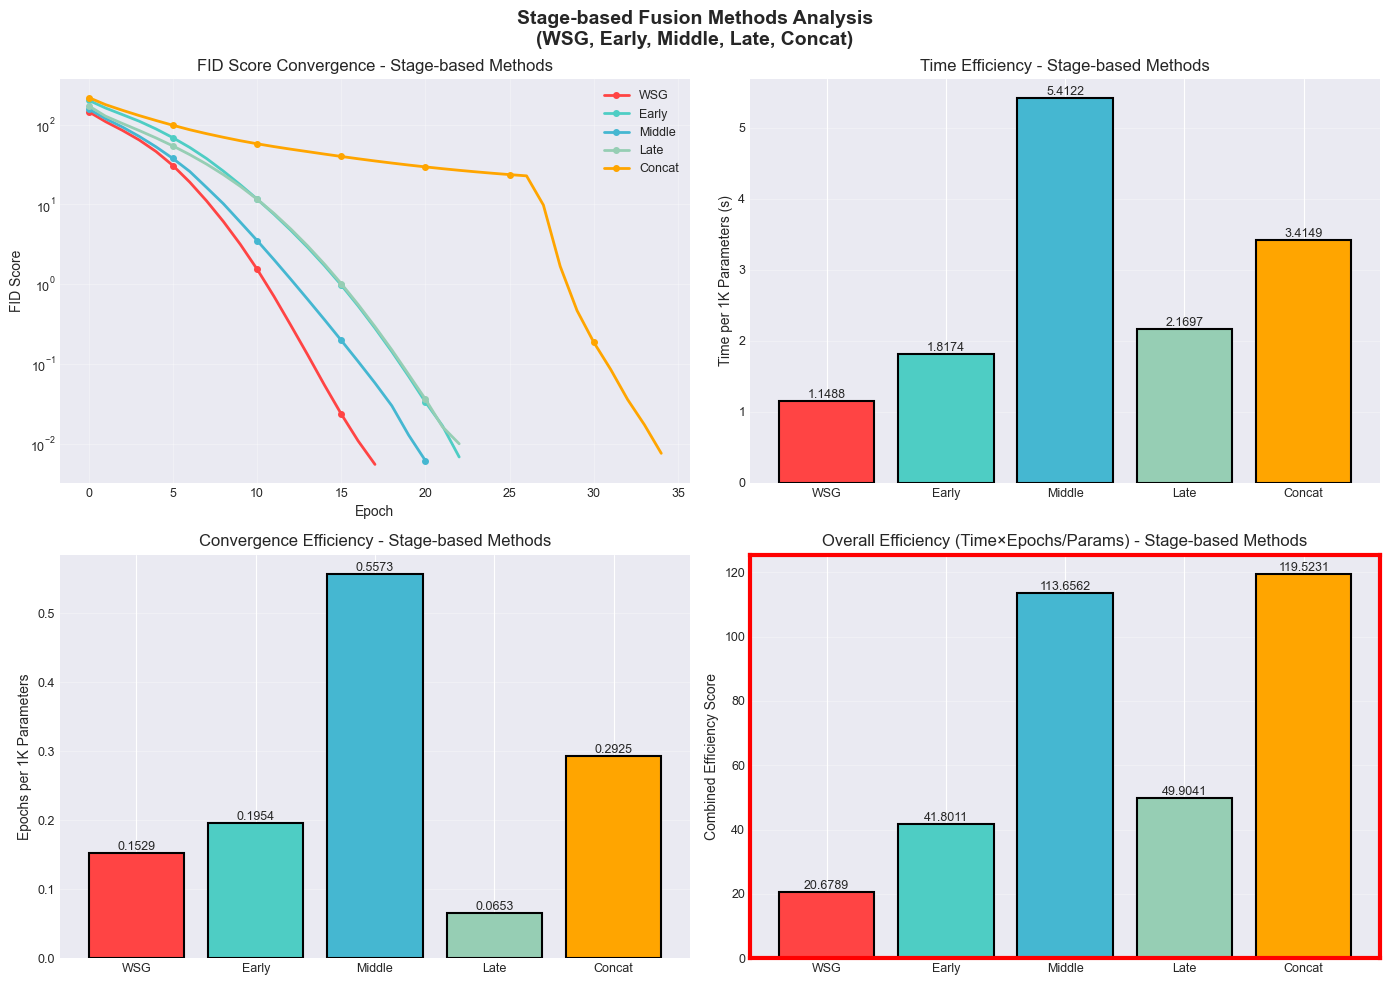

STAGE-BASED METHODS SUMMARY (First 5 Methods)
Method         Params   Epochs    Time(s)        FID    Combined Eff
------------------------------------------------------------
WSG           117,715       18     135.23     0.0055         20.6789
Early         117,715       23     213.94     0.0068         41.8011
Middle         37,683       21     203.95     0.0061        113.6562
Late          352,179       23     764.14     0.0099         49.9041
Concat        119,651       35     408.60     0.0075        119.5231

🏆 Best Stage-based Method: WSG
   Combined Efficiency: 20.6789


In [61]:
import matplotlib.pyplot as plt
import numpy as np

# Stage-based Methods: WSG, Early, Middle, Late, Concat (First 5 methods)
stage_methods = ['WSG', 'Early', 'Middle', 'Late', 'Concat']

# Filter results for stage methods
stage_results = {k: v for k, v in results.items() if k in stage_methods}

# Create figure with 4 subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Define colors for each method
colors = {
    'WSG': '#FF4444',      # Bright Red
    'Early': '#4ECDC4',    # Teal
    'Middle': '#45B7D1',   # Sky Blue
    'Late': '#96CEB4',     # Sage Green
    'Concat': '#FFA500'    # Orange
}

# 1. FID Curves Over Epochs
ax1 = axes[0, 0]
for method in stage_methods:
    if method in stage_results:
        ax1.plot(stage_results[method]['fid_scores'], 
                label=method, 
                color=colors[method], 
                linewidth=2, 
                marker='o', 
                markersize=4, 
                markevery=5)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('FID Score')
ax1.set_title('FID Score Convergence - Stage-based Methods')
ax1.set_yscale('log')
ax1.legend(loc='best')
ax1.grid(True, alpha=0.3)

# 2. Time Efficiency (Time/Parameters)
ax2 = axes[0, 1]
x_pos = np.arange(len(stage_methods))
time_efficiency = []
method_labels = []

for method in stage_methods:
    if method in stage_results:
        efficiency = stage_results[method]['training_time'] / stage_results[method]['params'] * 1000
        time_efficiency.append(efficiency)
        method_labels.append(method)

bars = ax2.bar(range(len(method_labels)), time_efficiency, 
              color=[colors[m] for m in method_labels],
              edgecolor='black', linewidth=1.5)

ax2.set_ylabel('Time per 1K Parameters (s)')
ax2.set_title('Time Efficiency - Stage-based Methods')
ax2.set_xticks(range(len(method_labels)))
ax2.set_xticklabels(method_labels)
ax2.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bar, val in zip(bars, time_efficiency):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
            f'{val:.4f}', ha='center', va='bottom', fontsize=9)

# 3. Convergence Efficiency (Epochs/Parameters)
ax3 = axes[1, 0]
epochs_efficiency = []

for method in stage_methods:
    if method in stage_results:
        efficiency = stage_results[method]['epochs_trained'] / stage_results[method]['params'] * 1000
        epochs_efficiency.append(efficiency)

bars = ax3.bar(range(len(method_labels)), epochs_efficiency,
              color=[colors[m] for m in method_labels],
              edgecolor='black', linewidth=1.5)

ax3.set_ylabel('Epochs per 1K Parameters')
ax3.set_title('Convergence Efficiency - Stage-based Methods')
ax3.set_xticks(range(len(method_labels)))
ax3.set_xticklabels(method_labels)
ax3.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bar, val in zip(bars, epochs_efficiency):
    height = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2., height,
            f'{val:.4f}', ha='center', va='bottom', fontsize=9)

# 4. Combined Efficiency (Time×Epochs/Parameters) - WITH RED BORDER
ax4 = axes[1, 1]
combined_efficiency = []

for method in stage_methods:
    if method in stage_results:
        efficiency = (stage_results[method]['training_time'] * stage_results[method]['epochs_trained']) / stage_results[method]['params'] * 1000
        combined_efficiency.append(efficiency)

bars = ax4.bar(range(len(method_labels)), combined_efficiency,
              color=[colors[m] for m in method_labels],
              edgecolor='black', linewidth=1.5)

ax4.set_ylabel('Combined Efficiency Score')
ax4.set_title('Overall Efficiency (Time×Epochs/Params) - Stage-based Methods')
ax4.set_xticks(range(len(method_labels)))
ax4.set_xticklabels(method_labels)
ax4.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bar, val in zip(bars, combined_efficiency):
    height = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width()/2., height,
            f'{val:.4f}', ha='center', va='bottom', fontsize=9)

# Add red border to bottom-right subplot
for spine in ax4.spines.values():
    spine.set_edgecolor('red')
    spine.set_linewidth(3)

plt.suptitle('Stage-based Fusion Methods Analysis\n(WSG, Early, Middle, Late, Concat)', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Print summary statistics
print("="*60)
print("STAGE-BASED METHODS SUMMARY (First 5 Methods)")
print("="*60)
print(f"{'Method':<10} {'Params':>10} {'Epochs':>8} {'Time(s)':>10} {'FID':>10} {'Combined Eff':>15}")
print("-"*60)

for method in stage_methods:
    if method in stage_results:
        r = stage_results[method]
        print(f"{method:<10} {r['params']:>10,} {r['epochs_trained']:>8} "
              f"{r['training_time']:>10.2f} {r['final_fid']:>10.4f} "
              f"{r['combined_efficiency']:>15.4f}")

# Find best performer
best_method = min(stage_results.keys(), key=lambda x: stage_results[x]['combined_efficiency'])
print(f"\n🏆 Best Stage-based Method: {best_method}")
print(f"   Combined Efficiency: {stage_results[best_method]['combined_efficiency']:.4f}")
print("="*60)

## 6. Strategy-based Methods Analysis

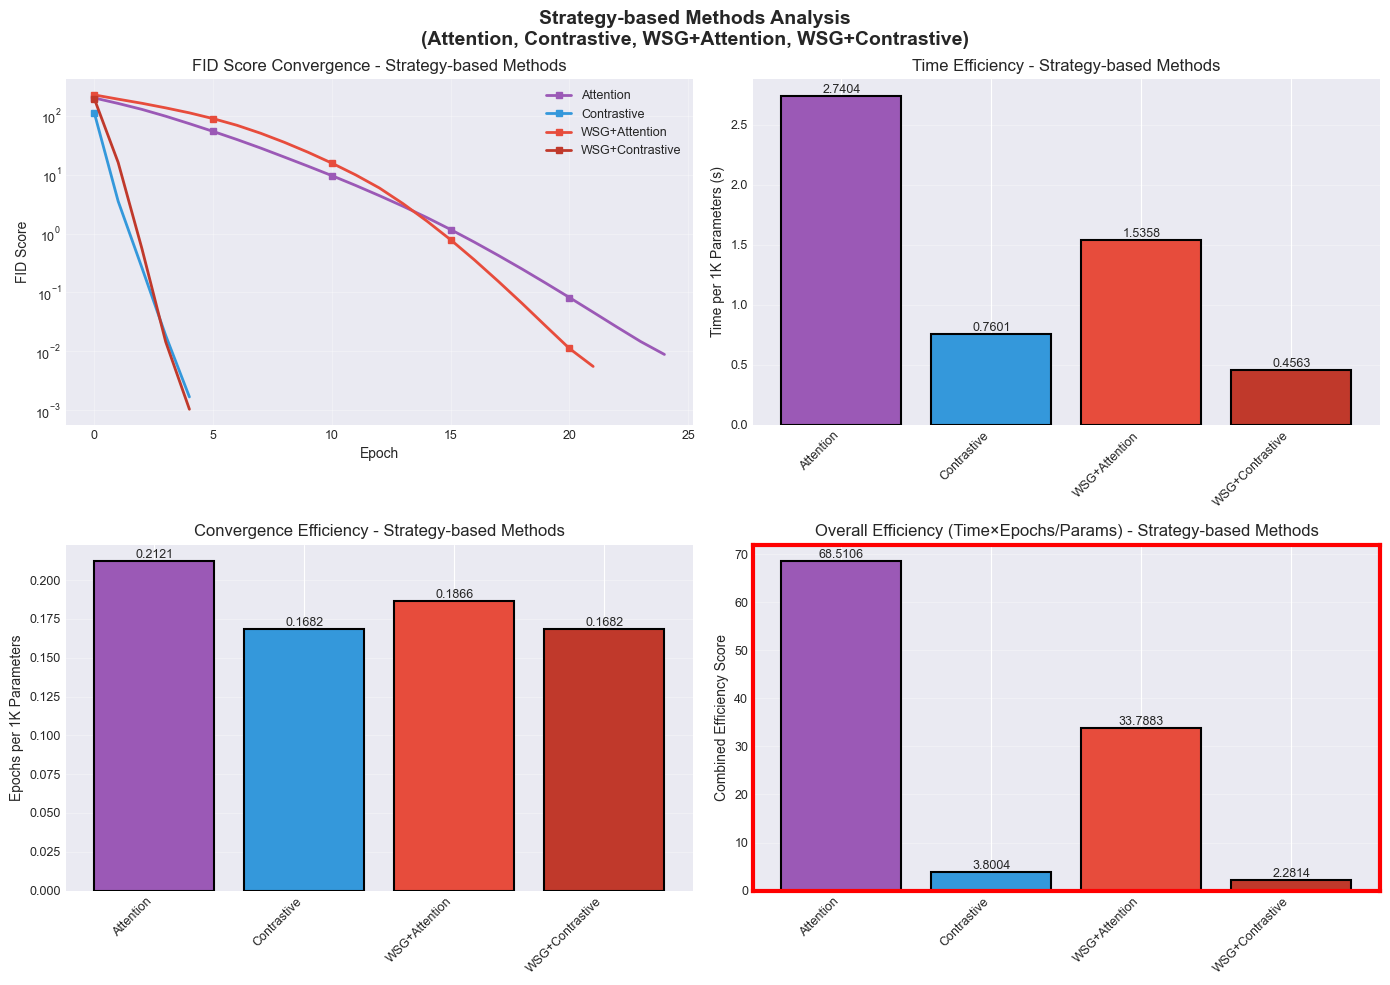

STRATEGY-BASED METHODS SUMMARY (Last 4 Methods)
Method              Params   Epochs    Time(s)        FID    Combined Eff
------------------------------------------------------------
Attention          117,875       25     323.03     0.0088         68.5106
Contrastive         29,731        5      22.60     0.0017          3.8004
WSG+Attention      117,875       22     181.04     0.0055         33.7883
WSG+Contrastive     29,731        5      13.57     0.0010          2.2814

🏆 Best Strategy-based Method: WSG+Contrastive
   Combined Efficiency: 2.2814

📊 Strategy Comparison:
   WSG-based Strategies Average: 18.0348
   Traditional Strategies Average: 36.1555
   ✅ WSG-based strategies are 100.5% more efficient


In [62]:
import matplotlib.pyplot as plt
import numpy as np

# Strategy-based Methods: Attention, Contrastive, WSG+Attention, WSG+Contrastive (Last 4 methods)
strategy_methods = ['Attention', 'Contrastive', 'WSG+Attention', 'WSG+Contrastive']

# Filter results for strategy methods
strategy_results = {k: v for k, v in results.items() if k in strategy_methods}

# Create figure with 4 subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Define colors for each method
colors = {
    'Attention': '#9B59B6',           # Purple
    'Contrastive': '#3498DB',         # Blue
    'WSG+Attention': '#E74C3C',       # Red
    'WSG+Contrastive': '#C0392B'      # Dark Red
}

# 1. FID Curves Over Epochs
ax1 = axes[0, 0]
for method in strategy_methods:
    if method in strategy_results:
        ax1.plot(strategy_results[method]['fid_scores'], 
                label=method, 
                color=colors[method], 
                linewidth=2, 
                marker='s', 
                markersize=4, 
                markevery=5)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('FID Score')
ax1.set_title('FID Score Convergence - Strategy-based Methods')
ax1.set_yscale('log')
ax1.legend(loc='best')
ax1.grid(True, alpha=0.3)

# 2. Time Efficiency (Time/Parameters)
ax2 = axes[0, 1]
x_pos = np.arange(len(strategy_methods))
time_efficiency = []
method_labels = []

for method in strategy_methods:
    if method in strategy_results:
        efficiency = strategy_results[method]['training_time'] / strategy_results[method]['params'] * 1000
        time_efficiency.append(efficiency)
        method_labels.append(method)

bars = ax2.bar(range(len(method_labels)), time_efficiency, 
              color=[colors[m] for m in method_labels],
              edgecolor='black', linewidth=1.5)

ax2.set_ylabel('Time per 1K Parameters (s)')
ax2.set_title('Time Efficiency - Strategy-based Methods')
ax2.set_xticks(range(len(method_labels)))
ax2.set_xticklabels(method_labels, rotation=45, ha='right')
ax2.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bar, val in zip(bars, time_efficiency):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
            f'{val:.4f}', ha='center', va='bottom', fontsize=9)

# 3. Convergence Efficiency (Epochs/Parameters)
ax3 = axes[1, 0]
epochs_efficiency = []

for method in strategy_methods:
    if method in strategy_results:
        efficiency = strategy_results[method]['epochs_trained'] / strategy_results[method]['params'] * 1000
        epochs_efficiency.append(efficiency)

bars = ax3.bar(range(len(method_labels)), epochs_efficiency,
              color=[colors[m] for m in method_labels],
              edgecolor='black', linewidth=1.5)

ax3.set_ylabel('Epochs per 1K Parameters')
ax3.set_title('Convergence Efficiency - Strategy-based Methods')
ax3.set_xticks(range(len(method_labels)))
ax3.set_xticklabels(method_labels, rotation=45, ha='right')
ax3.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bar, val in zip(bars, epochs_efficiency):
    height = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2., height,
            f'{val:.4f}', ha='center', va='bottom', fontsize=9)

# 4. Combined Efficiency (Time×Epochs/Parameters) - WITH RED BORDER
ax4 = axes[1, 1]
combined_efficiency = []

for method in strategy_methods:
    if method in strategy_results:
        efficiency = (strategy_results[method]['training_time'] * strategy_results[method]['epochs_trained']) / strategy_results[method]['params'] * 1000
        combined_efficiency.append(efficiency)

bars = ax4.bar(range(len(method_labels)), combined_efficiency,
              color=[colors[m] for m in method_labels],
              edgecolor='black', linewidth=1.5)

ax4.set_ylabel('Combined Efficiency Score')
ax4.set_title('Overall Efficiency (Time×Epochs/Params) - Strategy-based Methods')
ax4.set_xticks(range(len(method_labels)))
ax4.set_xticklabels(method_labels, rotation=45, ha='right')
ax4.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bar, val in zip(bars, combined_efficiency):
    height = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width()/2., height,
            f'{val:.4f}', ha='center', va='bottom', fontsize=9)

# Add red border to bottom-right subplot
for spine in ax4.spines.values():
    spine.set_edgecolor('red')
    spine.set_linewidth(3)

plt.suptitle('Strategy-based Methods Analysis\n(Attention, Contrastive, WSG+Attention, WSG+Contrastive)', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Print summary statistics
print("="*60)
print("STRATEGY-BASED METHODS SUMMARY (Last 4 Methods)")
print("="*60)
print(f"{'Method':<15} {'Params':>10} {'Epochs':>8} {'Time(s)':>10} {'FID':>10} {'Combined Eff':>15}")
print("-"*60)

for method in strategy_methods:
    if method in strategy_results:
        r = strategy_results[method]
        print(f"{method:<15} {r['params']:>10,} {r['epochs_trained']:>8} "
              f"{r['training_time']:>10.2f} {r['final_fid']:>10.4f} "
              f"{r['combined_efficiency']:>15.4f}")

# Find best performer
best_method = min(strategy_results.keys(), key=lambda x: strategy_results[x]['combined_efficiency'])
print(f"\n🏆 Best Strategy-based Method: {best_method}")
print(f"   Combined Efficiency: {strategy_results[best_method]['combined_efficiency']:.4f}")

# Compare WSG-based strategies vs traditional strategies
wsg_strategies = ['WSG+Attention', 'WSG+Contrastive']
traditional_strategies = ['Attention', 'Contrastive']

wsg_avg = np.mean([strategy_results[m]['combined_efficiency'] for m in wsg_strategies if m in strategy_results])
trad_avg = np.mean([strategy_results[m]['combined_efficiency'] for m in traditional_strategies if m in strategy_results])

print(f"\n📊 Strategy Comparison:")
print(f"   WSG-based Strategies Average: {wsg_avg:.4f}")
print(f"   Traditional Strategies Average: {trad_avg:.4f}")

if wsg_avg < trad_avg:
    improvement = ((trad_avg / wsg_avg) - 1) * 100
    print(f"   ✅ WSG-based strategies are {improvement:.1f}% more efficient")
else:
    degradation = ((wsg_avg / trad_avg) - 1) * 100
    print(f"   ❌ WSG-based strategies are {degradation:.1f}% less efficient")

print("="*60)